# Trabajo Práctico 2: Aprendizaje Supervisado
## Comparación de modelos clásicos de clasificación

**Dataset:** Breast Cancer Wisconsin (Diagnostic) — Kaggle  
**Objetivo:** comparar modelos de clasificación binaria mediante ROC AUC y validación cruzada.

En este notebook se inicia el experimento: carga y revisión de los datos, limpieza básica, exploración, división en entrenamiento/validación/prueba y preparación del pipeline de preprocesamiento.



## 1. Fuente de los datos

Descargaremos el archivo CSV desde el dataset público de Kaggle:

- [Breast Cancer Wisconsin (Diagnostic) Data Set — Kaggle](https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data)

Después de descargarlo, coloca el archivo `data.csv` en la misma carpeta de este notebook. En la versión habitual del dataset, el diagnóstico aparece como `B` (benigno) o `M` (maligno); además puede haber una columna identificadora y una columna vacía llamadas `id` y `Unnamed: 32`. El código revisa y elimina esas columnas si están presentes.

## 2. Preparación del entorno

En la terminal integrada de VS Code, instala las librerías necesarias una sola vez:

```bash
python -m pip install pandas numpy matplotlib seaborn scikit-learn jupyter
```

Luego selecciona el kernel de Python de tu entorno en VS Code y ejecuta las celdas en orden.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score

SEED = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


## 3. Cargar el dataset

El código intenta encontrar `data.csv`. Si el archivo descargado tiene otro nombre, también acepta ese nombre cuando es el único CSV de la carpeta. Comprueba que el archivo cargado sea el correcto antes de continuar.

In [6]:
df = pd.read_csv(r"C:\Users\JOSE DANIEL\Documents\ciencia de datos\data.csv")
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [8]:
from pathlib import Path

ruta = Path(
    r"C:\Users\JOSE DANIEL\Documents\ciencia de datos\data.csv"
)

print(ruta.exists())

True


## 4. Revisión y limpieza básica

Primero estandarizamos los nombres de las columnas, eliminamos columnas vacías o identificadores y verificamos la variable objetivo. Luego convertimos los predictores a formato numérico y revisamos valores faltantes y registros duplicados.

Para este trabajo se codificará `diagnosis` como:

- `0`: benigno (`B`)
- `1`: maligno (`M`)

Esta codificación facilita el cálculo de ROC AUC y mantiene una interpretación coherente del resultado.

In [11]:
# Crear una copia para conservar los datos originales
df_limpio = df.copy()

# 1. Estandarizar los nombres de las columnas
df_limpio.columns = (
    df_limpio.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

# 2. Eliminar identificadores y columnas vacías
columnas_eliminar = [
    columna for columna in df_limpio.columns
    if columna == "id" or columna.startswith("unnamed")
]

df_limpio = df_limpio.drop(columns=columnas_eliminar)

# 3. Verificar que exista la variable objetivo
if "diagnosis" not in df_limpio.columns:
    raise ValueError("No se encontró la columna 'diagnosis'.")

# 4. Codificar la variable objetivo
# 4. Verificar y codificar la variable objetivo

if "diagnosis" not in df_limpio.columns:
    raise ValueError("No se encontró la columna 'diagnosis'.")

# Normalizar los valores originales
diagnostico = (
    df_limpio["diagnosis"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Codificar las categorías y admitir valores ya numéricos
mapa_diagnostico = {
    "B": 0,
    "M": 1,
    "BENIGN": 0,
    "MALIGNANT": 1,
    "0": 0,
    "1": 1,
    "0.0": 0,
    "1.0": 1
}

df_limpio["diagnosis"] = diagnostico.map(mapa_diagnostico)

# Comprobar que todos los valores se hayan codificado
if df_limpio["diagnosis"].isna().any():
    valores_invalidos = diagnostico[
        df_limpio["diagnosis"].isna()
    ].unique()

    raise ValueError(
        f"Se encontraron diagnósticos no reconocidos: {valores_invalidos}"
    )

# Convertir la variable objetivo a entero
df_limpio["diagnosis"] = df_limpio["diagnosis"].astype(int)

print("Codificación realizada correctamente.")
print("0 = Benigno (B)")
print("1 = Maligno (M)")
print("\nDistribución del diagnóstico:")
print(df_limpio["diagnosis"].value_counts())

# 5. Convertir las variables predictoras a formato numérico
predictoras = df_limpio.columns.drop("diagnosis")

df_limpio[predictoras] = df_limpio[predictoras].apply(
    pd.to_numeric,
    errors="coerce"
)

# 6. Revisar valores faltantes
print("Valores faltantes por columna:")
print(df_limpio.isnull().sum()[df_limpio.isnull().sum() > 0])

# 7. Revisar registros duplicados
print("\nCantidad de registros duplicados:", df_limpio.duplicated().sum())

# 8. Mostrar el resultado
print("\nDimensiones de la base limpia:", df_limpio.shape)
print("\nDistribución del diagnóstico:")
print(df_limpio["diagnosis"].value_counts())

display(df_limpio.head())


Codificación realizada correctamente.
0 = Benigno (B)
1 = Maligno (M)

Distribución del diagnóstico:
diagnosis
0    357
1    212
Name: count, dtype: int64
Valores faltantes por columna:
Series([], dtype: int64)

Cantidad de registros duplicados: 0

Dimensiones de la base limpia: (569, 31)

Distribución del diagnóstico:
diagnosis
0    357
1    212
Name: count, dtype: int64


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 5. Exploración inicial de los datos

Revisamos los tipos de variables, el resumen estadístico y la distribución de las dos clases. Esta exploración permite verificar que la variable objetivo esté bien codificada e identificar si las clases están desbalanceadas.


Dimensiones del dataset:
Número de filas: 569
Número de columnas: 31

Información general del dataset:
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    int64  
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave_points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    f

,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture_mean,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter_mean,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area_mean,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness_mean,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness_mean,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity_mean,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave_points_mean,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry_mean,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
fractal_dimension_mean,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744



Valores únicos de diagnosis:
[np.int64(0), np.int64(1)]

Distribución de los diagnósticos:


,Cantidad,Porcentaje (%)
Benigno (0),357,62.74
Maligno (1),212,37.26


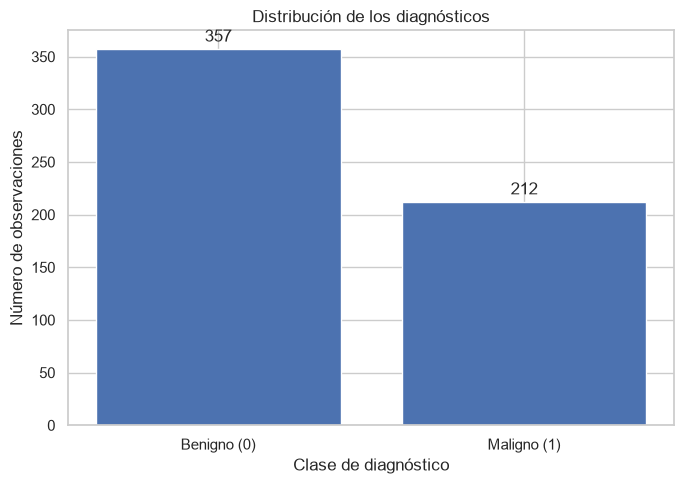

In [13]:

# 5.1 Definir las variables predictoras y la variable objetivo
X = df_limpio.drop(columns=["diagnosis"])
y = df_limpio["diagnosis"]

# 5.2 Revisar las dimensiones y los tipos de variables
print("Dimensiones del dataset:")
print(f"Número de filas: {df_limpio.shape[0]}")
print(f"Número de columnas: {df_limpio.shape[1]}")

print("\nInformación general del dataset:")
df_limpio.info()

# 5.3 Resumen estadístico de los predictores
print("\nResumen estadístico de los predictores:")
display(X.describe().T)

# 5.4 Verificar la codificación de la variable objetivo
print("\nValores únicos de diagnosis:")
print(sorted(y.dropna().unique()))

# 5.5 Revisar la distribución de las dos clases
conteo_clases = y.value_counts().reindex([0, 1], fill_value=0)

resumen_clases = pd.DataFrame({
    "Cantidad": conteo_clases,
    "Porcentaje (%)": (
        conteo_clases / len(y) * 100
    ).round(2)
})

resumen_clases.index = ["Benigno (0)", "Maligno (1)"]

print("\nDistribución de los diagnósticos:")
display(resumen_clases)

# 5.6 Visualizar la distribución de las clases
plt.figure(figsize=(7, 5))

barras = plt.bar(
    ["Benigno (0)", "Maligno (1)"],
    conteo_clases.values
)

plt.title("Distribución de los diagnósticos")
plt.xlabel("Clase de diagnóstico")
plt.ylabel("Número de observaciones")
plt.bar_label(barras, padding=3)

plt.tight_layout()
plt.show()


### Interpretación inicial

### Interpretación inicial

El dataset contiene 30 variables predictoras numéricas y una variable objetivo que clasifica los diagnósticos como benignos o malignos. La distribución presenta 357 casos benignos (62,7 %) y 212 malignos (37,3 %). Además, las variables tienen diferentes escalas de medición, por lo que aplicaremos `StandardScaler` y una división estratificada para conservar la proporción de las clases en los conjuntos de entrenamiento, validación y prueba.

## 6. División en entrenamiento, validación y prueba

Se utilizará una distribución aproximada de 70 % para entrenamiento, 15 % para validación y 15 % para prueba. La estratificación conserva aproximadamente la proporción de las clases en las tres particiones.

El conjunto de prueba quedará reservado hasta la etapa final; no se utilizará para decidir qué modelo elegir.

In [14]:
# Primera separación: 70 % entrenamiento y 30 % temporal.
X_train, X_temporal, y_train, y_temporal = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

# Segunda separación: dividir la parte temporal por igual para validación y prueba.
X_val, X_test, y_val, y_test = train_test_split(
    X_temporal,
    y_temporal,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temporal
)

particiones = pd.DataFrame({
    "conjunto": ["Entrenamiento", "Validación", "Prueba"],
    "observaciones": [len(X_train), len(X_val), len(X_test)],
    "porcentaje_dataset": [
        100 * len(X_train) / len(X),
        100 * len(X_val) / len(X),
        100 * len(X_test) / len(X)
    ],
    "porcentaje_clase_maligna": [
        100 * y_train.mean(),
        100 * y_val.mean(),
        100 * y_test.mean()
    ]
})
display(particiones.round(2))

print("Tamaños de X:", X_train.shape, X_val.shape, X_test.shape)
print("Tamaños de y:", y_train.shape, y_val.shape, y_test.shape)

,conjunto,observaciones,porcentaje_dataset,porcentaje_clase_maligna
0,Entrenamiento,398,69.95,37.19
1,Validación,85,14.94,37.65
2,Prueba,86,15.11,37.21


Tamaños de X: (398, 30) (85, 30) (86, 30)
Tamaños de y: (398,) (85,) (86,)


## 7. Preparar el pipeline de preprocesamiento y los modelos

`StandardScaler` estandariza los predictores numéricos. Lo incluimos dentro de un `Pipeline` para que, más adelante, durante la validación cruzada, el escalador se ajuste únicamente con los datos de entrenamiento de cada fold y no utilice información de la partición de evaluación.

Compararemos tres modelos clásicos con hiperparámetros por defecto: Regresión Logística, K Vecinos más Cercanos y Árbol de Decisión. La estandarización es especialmente importante para los dos primeros; se mantiene en el pipeline común para respetar el requisito de preprocesamiento del taller.

In [15]:
def crear_pipeline(modelo):
    """Construye un pipeline con estandarización y un clasificador."""
    return Pipeline(steps=[
        ("escalador", StandardScaler()),
        ("modelo", modelo)
    ])

modelos = {
    "Regresión Logística": LogisticRegression(),
    "K Vecinos más Cercanos": KNeighborsClassifier(),
    "Árbol de Decisión": DecisionTreeClassifier()
}

pipelines = {
    nombre: crear_pipeline(modelo)
    for nombre, modelo in modelos.items()
}

print("Pipelines preparados:")
for nombre, pipeline in pipelines.items():
    print(f"- {nombre}: {pipeline}")

Pipelines preparados:
- Regresión Logística: Pipeline(steps=[('escalador', StandardScaler()),
                ('modelo', LogisticRegression())])
- K Vecinos más Cercanos: Pipeline(steps=[('escalador', StandardScaler()),
                ('modelo', KNeighborsClassifier())])
- Árbol de Decisión: Pipeline(steps=[('escalador', StandardScaler()),
                ('modelo', DecisionTreeClassifier())])


## 8. Próxima etapa

Con esta preparación lista, la siguiente etapa será entrenar cada modelo con `X_train` y `y_train`, calcular ROC AUC en entrenamiento y validación, y efectuar validación cruzada estratificada de cinco folds con el conjunto de entrenamiento. Después organizaremos las métricas en una tabla comparativa y un gráfico.

In [18]:
# 8.1 Configurar la validación cruzada
SEED = 42

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)


# Diccionarios para almacenar los resultados
resultados_cv = {}
resultados_comparacion = []


# 8.2 ENTRENAR Y EVALUAR CADA MODELO

for nombre, pipeline in pipelines.items():

    print(f"\nEvaluando modelo: {nombre}")

    # A. Entrenar el modelo con el conjunto de entrenamiento
    pipeline.fit(X_train, y_train)

    # B. Calcular ROC AUC en entrenamiento
    prob_train = pipeline.predict_proba(X_train)[:, 1]
    auc_train = roc_auc_score(y_train, prob_train)

    # C. Calcular ROC AUC en validación
    prob_val = pipeline.predict_proba(X_val)[:, 1]
    auc_val = roc_auc_score(y_val, prob_val)
    
     # D. Realizar validación cruzada de 5 folds
    # El pipeline se ajusta dentro de cada fold.
    # Así se evita la fuga de información durante la estandarización.
    scores_cv = cross_val_score(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring="roc_auc"
    )

    # Guardar los resultados individuales de cada fold
    resultados_cv[nombre] = scores_cv

    # E. Calcular promedio y desviación estándar
    promedio_cv = scores_cv.mean()
    desviacion_cv = scores_cv.std()

    # F. Mostrar los resultados del modelo
    print(f"ROC AUC entrenamiento: {auc_train:.4f}")
    print(f"ROC AUC validación:    {auc_val:.4f}")
    
    print("ROC AUC por fold:")
    for i, score in enumerate(scores_cv, start=1):
        print(f"  Fold {i}: {score:.4f}")

    print(f"Promedio CV:           {promedio_cv:.4f}")
    print(f"Desviación estándar:   {desviacion_cv:.4f}")

    # G. Almacenar los resultados para la tabla comparativa
    fila = {
        "Modelo": nombre,
        "ROC AUC entrenamiento": auc_train,
        "ROC AUC validación": auc_val,
        "Fold 1": scores_cv[0],
        "Fold 2": scores_cv[1],
        "Fold 3": scores_cv[2],
        "Fold 4": scores_cv[3],
        "Fold 5": scores_cv[4],
        "ROC AUC CV media": promedio_cv,
        "ROC AUC CV desviación estándar": desviacion_cv
    }

    resultados_comparacion.append(fila)
    
    # 8.3 CONSTRUIR LA TABLA COMPARATIVA


tabla_resultados = pd.DataFrame(resultados_comparacion)

# Ordenar los modelos según el promedio de ROC AUC en CV
tabla_resultados = tabla_resultados.sort_values(
    by="ROC AUC CV media",
    ascending=False
).reset_index(drop=True)

print("\nTABLA COMPARATIVA DE LOS MODELOS")

display(tabla_resultados.round(4))

    


Evaluando modelo: Regresión Logística
ROC AUC entrenamiento: 0.9972
ROC AUC validación:    0.9965
ROC AUC por fold:
  Fold 1: 0.9960
  Fold 2: 0.9967
  Fold 3: 0.9867
  Fold 4: 1.0000
  Fold 5: 0.9834
Promedio CV:           0.9926
Desviación estándar:   0.0064

Evaluando modelo: K Vecinos más Cercanos
ROC AUC entrenamiento: 0.9975
ROC AUC validación:    0.9779
ROC AUC por fold:
  Fold 1: 0.9950
  Fold 2: 0.9963
  Fold 3: 0.9810
  Fold 4: 0.9697
  Fold 5: 0.9769
Promedio CV:           0.9838
Desviación estándar:   0.0104

Evaluando modelo: Árbol de Decisión
ROC AUC entrenamiento: 1.0000
ROC AUC validación:    0.8561
ROC AUC por fold:
  Fold 1: 0.9200
  Fold 2: 0.9067
  Fold 3: 0.9567
  Fold 4: 0.8810
  Fold 5: 0.9210
Promedio CV:           0.9171
Desviación estándar:   0.0245

TABLA COMPARATIVA DE LOS MODELOS


,Modelo,ROC AUC entrenamiento,ROC AUC validación,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,ROC AUC CV media,ROC AUC CV desviación estándar
0,Regresión Logística,0.9972,0.9965,0.996,0.9967,0.9867,1.0000,0.9834,0.9926,0.0064
1,K Vecinos más Cercanos,0.9975,0.9779,0.995,0.9963,0.9810,0.9697,0.9769,0.9838,0.0104
2,Árbol de Decisión,1.0000,0.8561,0.920,0.9067,0.9567,0.8810,0.9210,0.9171,0.0245


### Interpretación de la comparación de modelos

Los resultados indican que la Regresión Logística presenta el mejor desempeño, con un ROC AUC promedio de 0.9926 en validación cruzada y una desviación estándar de 0.0064. Además, obtuvo un ROC AUC de 0.9965 en validación, lo que refleja una buena capacidad para distinguir entre las clases. KNN también mostró resultados favorables, aunque ligeramente inferiores. En cambio, el Árbol de Decisión presentó una diferencia importante entre entrenamiento y validación, lo que sugiere un posible sobreajuste. Por estas razones, se selecciona inicialmente la Regresión Logística, ya que combina un alto rendimiento con una mayor estabilidad en las distintas particiones.


# 9. Evaluación Final en el conjunto de Prueba

EVALUACIÓN FINAL
Modelo seleccionado: Regresión Logística
ROC AUC en prueba: 0.9988

Comparación de resultados:


,Evaluación,ROC AUC
0,Validación,0.9965
1,Validación cruzada (media),0.9926
2,Prueba final,0.9988



Diferencia entre prueba y validación cruzada: +0.0063
Diferencia entre prueba y validación: +0.0024


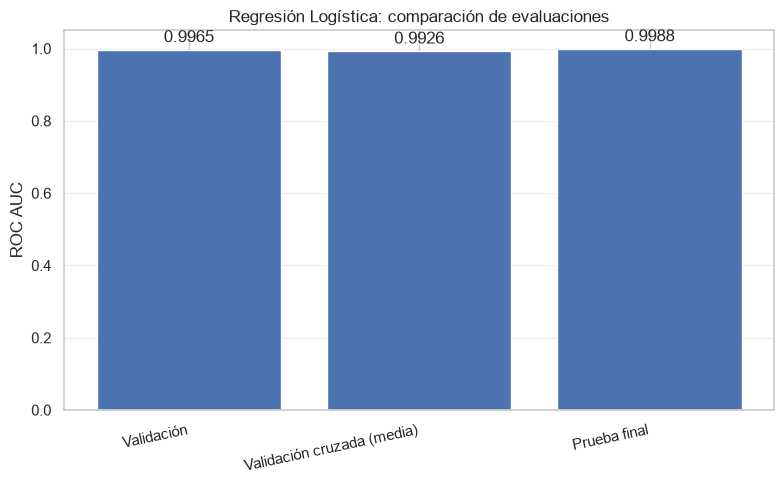

In [19]:

# 9.1 Crear un pipeline nuevo con Regresión Logística
modelo_final = crear_pipeline(LogisticRegression())

# 9.2 Entrenar con todos los datos del conjunto de entrenamiento
modelo_final.fit(X_train, y_train)

# 9.3 Predecir probabilidades para el conjunto de prueba
probabilidades_test = modelo_final.predict_proba(X_test)[:, 1]

# 9.4 Calcular ROC AUC en el conjunto de prueba
auc_test = roc_auc_score(y_test, probabilidades_test)

print("EVALUACIÓN FINAL")
print("Modelo seleccionado: Regresión Logística")
print(f"ROC AUC en prueba: {auc_test:.4f}")


# ============================================================
# 9.5 COMPARAR CON LOS RESULTADOS ANTERIORES
# ============================================================

# Recuperar los resultados previos de Regresión Logística
resultado_logistica = tabla_resultados.loc[
    tabla_resultados["Modelo"] == "Regresión Logística"
].iloc[0]

auc_validacion = resultado_logistica["ROC AUC validación"]
auc_cv_media = resultado_logistica["ROC AUC CV media"]

comparacion_final = pd.DataFrame({
    "Evaluación": [
        "Validación",
        "Validación cruzada (media)",
        "Prueba final"
    ],
    "ROC AUC": [
        auc_validacion,
        auc_cv_media,
        auc_test
    ]
})

print("\nComparación de resultados:")
display(comparacion_final.round(4))

# Diferencias respecto a la evaluación final
print(
    "\nDiferencia entre prueba y validación cruzada:",
    f"{auc_test - auc_cv_media:+.4f}"
)

print(
    "Diferencia entre prueba y validación:",
    f"{auc_test - auc_validacion:+.4f}"
)


# ============================================================
# 9.6 GRÁFICO DE COMPARACIÓN FINAL
# ============================================================

plt.figure(figsize=(8, 5))

barras = plt.bar(
    comparacion_final["Evaluación"],
    comparacion_final["ROC AUC"]
)

plt.bar_label(barras, fmt="%.4f", padding=3)
plt.title("Regresión Logística: comparación de evaluaciones")
plt.ylabel("ROC AUC")
plt.ylim(0, 1.05)
plt.xticks(rotation=12, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Interpretación de la evaluación final

La Regresión Logística obtuvo un ROC AUC de 0.9988 en el conjunto de prueba, resultado ligeramente superior al obtenido en validación (0.9965) y al promedio de validación cruzada (0.9926). Estos resultados muestran que el modelo mantiene una capacidad de discriminación muy alta al evaluar datos no utilizados durante su entrenamiento. Por tanto, su desempeño final es consistente con los resultados anteriores y respalda su selección como el modelo con mejor rendimiento general. Sin embargo, esta métrica mide la capacidad para distinguir entre las clases y no significa que todas las predicciones sean correctas.